# Milestone 3: Improving ResNet-18 (forward / away)
**LookAway Guard: screen privacy through head orientation. DMET 901 Computer Vision, GUC**

In Milestone 2 our ResNet-18 reached **macro-F1 0.891** on 4 unseen test people. The analysis showed two problems:
1. **It memorises the 12 training people:** train macro-F1 0.995, validation only 0.855.
2. **Most errors are close to the 20° line**, where forward and away look almost the same.

We test three improvements. The training settings (learning rates, epochs, batch size, loss) stay exactly as in Milestone 2.

| | Improvement | What we change | Why |
|---|---|---|---|
| **A** | Small-input ResNet-18 | The first convolution uses stride 1 and the first max-pool is removed. The network reads the 64 × 64 crop directly instead of an enlarged 224 × 224 copy | Keeps the fine detail of small faces |
| **B** | More training people | Add the face crops of the **300W-LP** head-pose dataset (thousands of people) to the training set. Validation and test stay the same BIWI people | 12 people are too few: the network learns faces instead of head direction |
| **C** | Attention blocks | A Squeeze-and-Excitation (SE) block inside each residual block of ResNet-18 | Lets the network focus on the channels that describe head direction |

Each improvement is run alone, then the promising ones are combined. Every experiment runs with **3 seeds** (42, 43, 44) and we report the mean ± standard deviation, because Milestone 2 showed that a single run can be lucky.

**Accepted vs. real errors.** A head at 19.9° is "forward" and at 20.1° "away"; nobody can see that difference.
Every wrong prediction is therefore sorted into one of two groups:
- **accepted error:** the head is between 17.5° and 22.5°, right at the 20° line;
- **real error:** a clearly forward head (below 17.5°) predicted away, or a clearly away head (above 22.5°) predicted forward.

**How to run:** *Run all*. The notebook downloads the data, trains every experiment, shows the results and exports the final model for the desktop app. Run it locally with a GPU (we used an RTX 4070 laptop GPU) or in Google Colab (*Runtime → Change runtime type → T4 GPU*).

## 1. Setup and data download
Same source as Milestones 1 and 2: the FSA-Net data archive on Google Drive contains the BIWI face crops and the 300W-LP face crops.
The corrected BIWI head angles come from the HeadPose+ repository on GitHub.

In [1]:
import copy, json, re, subprocess, time, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, f1_score
from torchvision.models import ResNet18_Weights, resnet18

DATA = Path("../data") if Path("../data").exists() else Path("data")
DATA.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
CKPT = Path("checkpoints"); CKPT.mkdir(exist_ok=True)

# Files we need, and where they are inside the FSA-Net archive
FILES = {
    "BIWI_noTrack.npz":      "data/BIWI_noTrack.npz",
    "300W_LP_AFW.npz":       "data/type1/AFW.npz",
    "300W_LP_HELEN.npz":     "data/type1/HELEN.npz",
    "300W_LP_IBUG.npz":      "data/type1/IBUG.npz",
    "300W_LP_LFPW.npz":      "data/type1/LFPW.npz",
}
missing = [name for name in FILES if not (DATA / name).exists()]
if missing:
    zip_path = DATA / "fsanet_data.zip"                   # about 1.4 GB
    if not zip_path.exists():
        subprocess.run(["pip", "-q", "install", "gdown"], check=True)
        import gdown
        gdown.download(id="1j6GMx33DCcbUOS8J3NHZ-BMHgk7H-oC_", output=str(zip_path))
    with zipfile.ZipFile(zip_path) as z:
        for name in missing:
            (DATA / name).write_bytes(z.read(FILES[name]))
if not (DATA / "headposeplus").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/kuhnkeF/headposeplus", str(DATA / "headposeplus")], check=True)

for name in FILES:
    print(f"{name:20} {(DATA / name).stat().st_size / 1e6:6.1f} MB")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("\nPyTorch", torch.__version__, "| device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

BIWI_noTrack.npz      162.8 MB
300W_LP_AFW.npz        64.1 MB
300W_LP_HELEN.npz     463.9 MB
300W_LP_IBUG.npz       22.0 MB
300W_LP_LFPW.npz      203.8 MB

PyTorch 2.14.1+cu126 | device: NVIDIA GeForce RTX 4070 Laptop GPU


## 2. Configuration
The training settings are **identical to Milestone 2**. Only the three switches in `EXPERIMENTS` change between experiments.

In [2]:
CFG = dict(
    threshold_deg=20,       # forward if |yaw| <= 20 and |pitch| <= 20
    batch_size=64,
    optimizer="Adam",
    stage1_epochs=5,        # stage 1: pretrained backbone frozen, train only the new layers
    stage1_lr=1e-3,
    stage2_epochs=10,       # stage 2: also fine-tune the last residual block (layer4)
    stage2_lr=1e-4,
    loss="weighted cross-entropy",
    model_selection="best validation macro-F1",
    seeds=[42, 43, 44],
    accepted_band_deg=2.5,  # errors between 17.5 and 22.5 deg count as "accepted"
)

# A = small input, B = 300W-LP training data, C = SE attention blocks
EXPERIMENTS = {
    "Baseline (MS2)":  dict(small_input=False, extra_300wlp=False, se=False),
    "A: Small input":  dict(small_input=True,  extra_300wlp=False, se=False),
    "B: + 300W-LP":    dict(small_input=False, extra_300wlp=True,  se=False),
    "C: SE attention": dict(small_input=False, extra_300wlp=False, se=True),
    "A + B":           dict(small_input=True,  extra_300wlp=True,  se=False),
    "A + B + C":       dict(small_input=True,  extra_300wlp=True,  se=True),
}

pd.DataFrame(EXPERIMENTS).T

,small_input,extra_300wlp,se
Baseline (MS2),False,False,False
A: Small input,True,False,False
B: + 300W-LP,False,True,False
C: SE attention,False,False,True
A + B,True,True,False
A + B + C,True,True,True


## 3. Data
**BIWI** is loaded, labelled and split exactly as in Milestone 2: by person, 12 / 4 / 4 people.
**300W-LP** is only added to the *training* set of experiments B, A + B and A + B + C.
Its head angles were estimated from photos and are less precise than BIWI's, so we leave out its images within 2.5° of the 20° line.

In [3]:
T = CFG["threshold_deg"]
BAND = CFG["accepted_band_deg"]

def label(yaw, pitch):
    # 1 = forward, 0 = away
    return ((np.abs(yaw) <= T) & (np.abs(pitch) <= T)).astype(np.int64)

def distance_to_line(yaw, pitch):
    # How far the head is from the 20 deg line (negative = forward side, positive = away side)
    return np.maximum(np.abs(yaw), np.abs(pitch)) - T

# ---- BIWI: 13,219 face crops of 20 people, 64 x 64, stored as BGR
biwi = np.load(DATA / "BIWI_noTrack.npz")
biwi_images = biwi["image"][..., ::-1]                         # BGR -> RGB
hpp = DATA / "headposeplus" / "data"
names = np.load(hpp / "Biwi_FSA-Net.npz")["images"]            # file name of every crop, same order as the crops
plus = np.load(hpp / "Biwi_plus.npz")                          # corrected angles, matched by file name
row = {name: i for i, name in enumerate(plus["images"])}
match = [row[name] for name in names]
biwi_pitch = plus["pyr"][match, 0]
biwi_yaw = plus["pyr"][match, 1]
recording = np.array([int(name[:2]) for name in names])        # BIWI recording number 1..24

# Same person-level split as Milestones 1 and 2. 4 people were recorded twice; both recordings stay in one split.
VAL_RECORDINGS = [6, 9, 16, 19]
TEST_RECORDINGS = [1, 2, 17, 20, 21]
split = np.full(len(names), "train")
split[np.isin(recording, VAL_RECORDINGS)] = "val"
split[np.isin(recording, TEST_RECORDINGS)] = "test"

# ---- 300W-LP: face crops with (yaw, pitch, roll) in degrees
lp_images, lp_yaw, lp_pitch = [], [], []
for part in ["AFW", "HELEN", "IBUG", "LFPW"]:
    d = np.load(DATA / f"300W_LP_{part}.npz")
    lp_images.append(d["image"][..., ::-1])                    # BGR -> RGB
    lp_yaw.append(d["pose"][:, 0])
    lp_pitch.append(d["pose"][:, 1])
lp_images, lp_yaw, lp_pitch = np.concatenate(lp_images), np.concatenate(lp_yaw), np.concatenate(lp_pitch)
keep = np.abs(distance_to_line(lp_yaw, lp_pitch)) > BAND
print(f"300W-LP: {len(lp_images):,} images, {(~keep).sum():,} within {BAND} deg of the line left out, {keep.sum():,} used")

# ---- One array with everything: BIWI first, then the 300W-LP images we use
images = np.concatenate([biwi_images, lp_images[keep]])
yaw = np.concatenate([biwi_yaw, lp_yaw[keep]])
pitch = np.concatenate([biwi_pitch, lp_pitch[keep]])
y = label(yaw, pitch)
dist = distance_to_line(yaw, pitch)

n_biwi = len(biwi_images)
idx = {
    "train": np.where(split == "train")[0],
    "300wlp": np.arange(n_biwi, len(images)),
    "val": np.where(split == "val")[0],
    "test": np.where(split == "test")[0],
}

# The BIWI numbers must match the Milestone 1 table
assert [(len(idx[s]), y[idx[s]].sum()) for s in ("train", "val", "test")] == [(8933, 2554), (2257, 892), (2029, 824)]

counts = pd.DataFrame({s: {"images": len(i), "forward": y[i].sum(), "away": len(i) - y[i].sum(),
                           "forward %": f"{y[i].mean():.1%}"} for s, i in idx.items()}).T
counts.index = ["BIWI train (12 people)", "300W-LP (extra training)", "BIWI validation (4 people)", "BIWI test (4 people)"]
in_band = np.abs(dist[idx["test"]]) <= BAND
print(f"Test images between {T - BAND} and {T + BAND} deg (errors there are 'accepted'): {in_band.sum()} of {len(in_band)}")
counts

300W-LP: 61,225 images, 3,414 within 2.5 deg of the line left out, 57,811 used


Test images between 17.5 and 22.5 deg (errors there are 'accepted'): 337 of 2029


,images,forward,away,forward %
BIWI train (12 people),8933,2554,6379,28.6%
300W-LP (extra training),57811,6077,51734,10.5%
BIWI validation (4 people),2257,892,1365,39.5%
BIWI test (4 people),2029,824,1205,40.6%


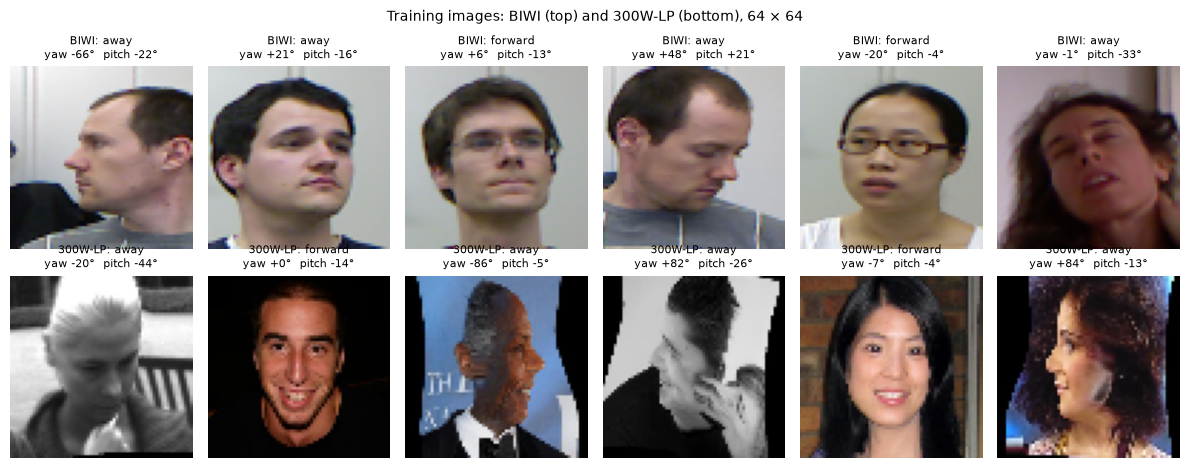

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.8))
rng = np.random.default_rng(0)
examples = list(rng.choice(idx["train"], 6, replace=False)) + list(rng.choice(idx["300wlp"], 6, replace=False))
for ax, i in zip(axes.flat, examples):
    ax.imshow(images[i])
    ax.axis("off")
    source = "BIWI" if i < n_biwi else "300W-LP"
    ax.set_title(f"{source}: {'forward' if y[i] else 'away'}\nyaw {yaw[i]:+.0f}°  pitch {pitch[i]:+.0f}°", fontsize=8)
plt.suptitle("Training images: BIWI (top) and 300W-LP (bottom), 64 × 64", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "samples.png", dpi=200); plt.show()

## 4. Model
All experiments start from the same ImageNet-pretrained ResNet-18 with a new 2-class output layer (away / forward).

- **Preprocessing** (as in Milestone 2): scale pixels to 0–1 and normalise with the ImageNet mean and standard deviation.
  The baseline enlarges the 64 × 64 crop to 224 × 224; the small-input model (A) uses the crop as it is.
- **SE block (C):** averages each channel, and a tiny 2-layer network turns that into one weight per channel.
  Its last layer starts at zero, so at the start every weight is exactly 1 and the pretrained network is unchanged.

In [5]:
X = torch.from_numpy(images).to(device)       # all images stay on the GPU as uint8
Y = torch.from_numpy(y).to(device)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def preprocess(batch, size):
    x = batch.permute(0, 3, 1, 2).float() / 255.0              # (N, 64, 64, 3) uint8 -> (N, 3, 64, 64) float
    if size != 64:
        x = F.interpolate(x, size=size, mode="bilinear", align_corners=False)
    return (x - MEAN) / STD


class SE(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.fc1 = nn.Linear(channels, channels // reduction)
        self.fc2 = nn.Linear(channels // reduction, channels)
        nn.init.zeros_(self.fc2.weight)
        nn.init.zeros_(self.fc2.bias)

    def forward(self, x):
        w = x.mean(dim=(2, 3))                                    # one number per channel
        w = 2 * torch.sigmoid(self.fc2(F.relu(self.fc1(w))))     # weight between 0 and 2 (starts at 1)
        return x * w[:, :, None, None]


def build_model(small_input, se):
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    if small_input:                     # A: read the 64 x 64 crop at full resolution
        model.conv1.stride = (1, 1)
        model.maxpool = nn.Identity()
    se_blocks = []
    if se:                              # C: an SE block at the end of each of the 8 residual blocks
        for layer in [model.layer1, model.layer2, model.layer3, model.layer4]:
            for block in layer:
                se_block = SE(block.bn2.num_features)
                block.bn2 = nn.Sequential(block.bn2, se_block)
                se_blocks.append(se_block)
    model.fc = nn.Linear(512, 2)        # new output layer: away / forward
    return model.to(device), se_blocks


def input_size(opts):
    return 64 if opts["small_input"] else 224


# Show what each model looks like
rows = {}
for name, opts in EXPERIMENTS.items():
    model, se_blocks = build_model(opts["small_input"], opts["se"])
    backbone = nn.Sequential(*list(model.children())[:-2])
    with torch.no_grad():
        features = backbone(preprocess(X[:1], input_size(opts)))
    rows[name] = {"input": f"{input_size(opts)} × {input_size(opts)}", "last feature map": " × ".join(map(str, features.shape[1:])),
                  "SE blocks": len(se_blocks), "parameters": f"{sum(p.numel() for p in model.parameters()):,}"}
del model
pd.DataFrame(rows).T

,input,last feature map,SE blocks,parameters
Baseline (MS2),224 × 224,512 × 7 × 7,0,"11,177,538"
A: Small input,64 × 64,512 × 8 × 8,0,"11,177,538"
B: + 300W-LP,224 × 224,512 × 7 × 7,0,"11,177,538"
C: SE attention,224 × 224,512 × 7 × 7,8,"11,266,618"
A + B,64 × 64,512 × 8 × 8,0,"11,177,538"
A + B + C,64 × 64,512 × 8 × 8,8,"11,266,618"


## 5. Training and evaluation
The same two-stage training as Milestone 2:
- **Stage 1** (5 epochs, learning rate 0.001): the pretrained network is frozen. Only the new output layer (and the new SE blocks) learn.
- **Stage 2** (10 epochs, learning rate 0.0001): the last residual block `layer4` learns as well.

The loss is cross-entropy weighted by class frequency in the training set. After every epoch we measure macro-F1 on the validation people and keep the best weights.
The test people are only used once, at the end.

In [6]:
use_amp = device.type == "cuda"          # mixed precision on the GPU (faster)


def predict(model, ids, size):
    model.eval()
    preds = []
    with torch.no_grad(), torch.autocast(device.type, enabled=use_amp):
        for batch in torch.from_numpy(ids).to(device).split(256):
            preds.append(model(preprocess(X[batch], size)).argmax(1))
    return torch.cat(preds).cpu().numpy()


def evaluate(true, pred, d):
    wrong = pred != true
    near_line = np.abs(d) <= BAND
    return dict(
        macro_f1=f1_score(true, pred, average="macro"),
        accuracy=1 - wrong.mean(),
        errors=int(wrong.sum()),
        accepted_errors=int((wrong & near_line).sum()),
        real_errors=int((wrong & ~near_line).sum()),
        forward_called_away=int((wrong & ~near_line & (true == 1)).sum()),
        away_called_forward=int((wrong & ~near_line & (true == 0)).sum()),
    )


def train_one_epoch(model, layers_to_train, optimizer, criterion, scaler, train_ids, size, generator):
    model.eval()                         # frozen layers keep their BatchNorm statistics
    for layer in layers_to_train:
        layer.train()
    order = torch.from_numpy(train_ids)[torch.randperm(len(train_ids), generator=generator)].to(device)
    total_loss, preds = 0.0, []
    for batch in order.split(CFG["batch_size"]):
        with torch.autocast(device.type, enabled=use_amp):
            out = model(preprocess(X[batch], size))
            loss = criterion(out, Y[batch])
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * len(batch)
        preds.append(out.argmax(1))
    train_f1 = f1_score(Y[order].cpu().numpy(), torch.cat(preds).cpu().numpy(), average="macro")
    return total_loss / len(order), train_f1


def run_experiment(name, seed):
    opts = EXPERIMENTS[name]
    torch.manual_seed(seed)
    np.random.seed(seed)
    model, se_blocks = build_model(opts["small_input"], opts["se"])
    size = input_size(opts)

    train_ids = idx["train"]
    if opts["extra_300wlp"]:
        train_ids = np.concatenate([idx["train"], idx["300wlp"]])
    n_per_class = np.bincount(y[train_ids])
    class_weights = torch.tensor(len(train_ids) / (2 * n_per_class), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    scaler = torch.amp.GradScaler(enabled=use_amp)
    generator = torch.Generator().manual_seed(seed)

    history, best_f1, best_state, best_epoch = [], -1.0, None, 0
    start = time.perf_counter()
    for stage in (1, 2):
        layers_to_train = [model.fc] + se_blocks
        if stage == 2:
            layers_to_train.append(model.layer4)
        for p in model.parameters():
            p.requires_grad = False
        for layer in layers_to_train:
            for p in layer.parameters():
                p.requires_grad = True
        optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=CFG[f"stage{stage}_lr"])

        for epoch in range(1, CFG[f"stage{stage}_epochs"] + 1):
            train_loss, train_f1 = train_one_epoch(model, layers_to_train, optimizer, criterion, scaler, train_ids, size, generator)
            val_f1 = f1_score(y[idx["val"]], predict(model, idx["val"], size), average="macro")
            history.append(dict(stage=stage, epoch=epoch, train_loss=train_loss, train_f1=train_f1, val_f1=val_f1))
            if val_f1 > best_f1:
                best_f1, best_state, best_epoch = val_f1, copy.deepcopy(model.state_dict()), len(history)

    model.load_state_dict(best_state)
    file_name = re.sub(r"[^A-Za-z0-9+]+", "_", name).strip("_")
    torch.save(best_state, CKPT / f"{file_name}_seed{seed}.pt")

    test_pred = predict(model, idx["test"], size)
    return dict(
        experiment=name, seed=seed, minutes=round((time.perf_counter() - start) / 60, 2), best_epoch=best_epoch,
        train_images=len(train_ids), history=history,
        train_f1=f1_score(y[idx["train"]], predict(model, idx["train"], size), average="macro"),   # the 12 BIWI training people
        val_f1=best_f1,
        test=evaluate(y[idx["test"]], test_pred, dist[idx["test"]]),
        test_pred=test_pred.tolist(),
    )

### Run all experiments
6 experiments × 3 seeds = 18 training runs. Each finished run is saved to `ms3_runs.json`,
so if the run stops, running this cell again continues where it stopped.

In [7]:
def show_log(key, run, loaded):
    # The training log of one run: one line per epoch, then the test result.
    print(f"=== {key} ===" + ("  (loaded from ms3_runs.json)" if loaded else ""))
    best = -1.0
    for h in run["history"]:
        note = "  <- best so far" if h["val_f1"] > best else ""
        best = max(best, h["val_f1"])
        print(f"  stage {h['stage']} epoch {h['epoch']:2d} | train loss {h['train_loss']:.3f}  train F1 {h['train_f1']:.3f}"
              f" | validation F1 {h['val_f1']:.3f}{note}")
    t = run["test"]
    print(f"=== {key}: {run['minutes']:.1f} min, best epoch {run['best_epoch']} | TEST macro-F1 {t['macro_f1']:.3f}, "
          f"accuracy {t['accuracy']:.1%}, errors {t['errors']} = {t['accepted_errors']} accepted + {t['real_errors']} real\n")


RUNS_FILE = Path("ms3_runs.json")
runs = json.loads(RUNS_FILE.read_text()) if RUNS_FILE.exists() else {}

for name in EXPERIMENTS:
    for seed in CFG["seeds"]:
        key = f"{name} | seed {seed}"
        loaded = key in runs
        if not loaded:
            runs[key] = run_experiment(name, seed)
            RUNS_FILE.write_text(json.dumps(runs, indent=1))
        show_log(key, runs[key], loaded)

=== Baseline (MS2) | seed 42 ===
  stage 1 epoch  1 | train loss 0.362  train F1 0.819 | validation F1 0.728  <- best so far
  stage 1 epoch  2 | train loss 0.235  train F1 0.883 | validation F1 0.756  <- best so far
  stage 1 epoch  3 | train loss 0.205  train F1 0.897 | validation F1 0.784  <- best so far
  stage 1 epoch  4 | train loss 0.185  train F1 0.904 | validation F1 0.744
  stage 1 epoch  5 | train loss 0.175  train F1 0.913 | validation F1 0.774
  stage 2 epoch  1 | train loss 0.166  train F1 0.937 | validation F1 0.661
  stage 2 epoch  2 | train loss 0.049  train F1 0.978 | validation F1 0.828  <- best so far
  stage 2 epoch  3 | train loss 0.039  train F1 0.983 | validation F1 0.823
  stage 2 epoch  4 | train loss 0.027  train F1 0.987 | validation F1 0.738
  stage 2 epoch  5 | train loss 0.028  train F1 0.987 | validation F1 0.812
  stage 2 epoch  6 | train loss 0.014  train F1 0.994 | validation F1 0.837  <- best so far
  stage 2 epoch  7 | train loss 0.023  train F1 0.9

=== Baseline (MS2) | seed 43 ===
  stage 1 epoch  1 | train loss 0.369  train F1 0.823 | validation F1 0.792  <- best so far
  stage 1 epoch  2 | train loss 0.239  train F1 0.883 | validation F1 0.791
  stage 1 epoch  3 | train loss 0.206  train F1 0.894 | validation F1 0.762
  stage 1 epoch  4 | train loss 0.188  train F1 0.906 | validation F1 0.788
  stage 1 epoch  5 | train loss 0.176  train F1 0.909 | validation F1 0.769
  stage 2 epoch  1 | train loss 0.179  train F1 0.937 | validation F1 0.878  <- best so far
  stage 2 epoch  2 | train loss 0.056  train F1 0.973 | validation F1 0.825
  stage 2 epoch  3 | train loss 0.036  train F1 0.983 | validation F1 0.800
  stage 2 epoch  4 | train loss 0.024  train F1 0.988 | validation F1 0.825
  stage 2 epoch  5 | train loss 0.021  train F1 0.991 | validation F1 0.844
  stage 2 epoch  6 | train loss 0.019  train F1 0.991 | validation F1 0.845
  stage 2 epoch  7 | train loss 0.018  train F1 0.993 | validation F1 0.810
  stage 2 epoch  8 | tr

=== Baseline (MS2) | seed 44 ===
  stage 1 epoch  1 | train loss 0.364  train F1 0.818 | validation F1 0.738  <- best so far
  stage 1 epoch  2 | train loss 0.240  train F1 0.882 | validation F1 0.734
  stage 1 epoch  3 | train loss 0.207  train F1 0.895 | validation F1 0.762  <- best so far
  stage 1 epoch  4 | train loss 0.189  train F1 0.904 | validation F1 0.758
  stage 1 epoch  5 | train loss 0.175  train F1 0.914 | validation F1 0.751
  stage 2 epoch  1 | train loss 0.183  train F1 0.936 | validation F1 0.884  <- best so far
  stage 2 epoch  2 | train loss 0.055  train F1 0.975 | validation F1 0.841
  stage 2 epoch  3 | train loss 0.038  train F1 0.982 | validation F1 0.824
  stage 2 epoch  4 | train loss 0.020  train F1 0.990 | validation F1 0.849
  stage 2 epoch  5 | train loss 0.025  train F1 0.990 | validation F1 0.789
  stage 2 epoch  6 | train loss 0.023  train F1 0.989 | validation F1 0.841
  stage 2 epoch  7 | train loss 0.015  train F1 0.995 | validation F1 0.829
  stage

=== A: Small input | seed 42 ===
  stage 1 epoch  1 | train loss 0.378  train F1 0.806 | validation F1 0.857  <- best so far
  stage 1 epoch  2 | train loss 0.245  train F1 0.875 | validation F1 0.856
  stage 1 epoch  3 | train loss 0.215  train F1 0.891 | validation F1 0.858  <- best so far
  stage 1 epoch  4 | train loss 0.198  train F1 0.898 | validation F1 0.851
  stage 1 epoch  5 | train loss 0.186  train F1 0.908 | validation F1 0.861  <- best so far
  stage 2 epoch  1 | train loss 0.143  train F1 0.943 | validation F1 0.917  <- best so far
  stage 2 epoch  2 | train loss 0.040  train F1 0.981 | validation F1 0.920  <- best so far
  stage 2 epoch  3 | train loss 0.034  train F1 0.985 | validation F1 0.916
  stage 2 epoch  4 | train loss 0.022  train F1 0.990 | validation F1 0.918
  stage 2 epoch  5 | train loss 0.022  train F1 0.989 | validation F1 0.893
  stage 2 epoch  6 | train loss 0.013  train F1 0.994 | validation F1 0.909
  stage 2 epoch  7 | train loss 0.015  train F1 0.9

=== A: Small input | seed 43 ===
  stage 1 epoch  1 | train loss 0.379  train F1 0.803 | validation F1 0.856  <- best so far
  stage 1 epoch  2 | train loss 0.246  train F1 0.877 | validation F1 0.872  <- best so far
  stage 1 epoch  3 | train loss 0.213  train F1 0.889 | validation F1 0.869
  stage 1 epoch  4 | train loss 0.197  train F1 0.898 | validation F1 0.868
  stage 1 epoch  5 | train loss 0.184  train F1 0.903 | validation F1 0.867
  stage 2 epoch  1 | train loss 0.166  train F1 0.939 | validation F1 0.911  <- best so far
  stage 2 epoch  2 | train loss 0.043  train F1 0.978 | validation F1 0.919  <- best so far
  stage 2 epoch  3 | train loss 0.031  train F1 0.985 | validation F1 0.914
  stage 2 epoch  4 | train loss 0.024  train F1 0.989 | validation F1 0.908
  stage 2 epoch  5 | train loss 0.016  train F1 0.994 | validation F1 0.904
  stage 2 epoch  6 | train loss 0.018  train F1 0.992 | validation F1 0.912
  stage 2 epoch  7 | train loss 0.014  train F1 0.995 | validation 

=== A: Small input | seed 44 ===
  stage 1 epoch  1 | train loss 0.410  train F1 0.783 | validation F1 0.799  <- best so far
  stage 1 epoch  2 | train loss 0.258  train F1 0.867 | validation F1 0.855  <- best so far
  stage 1 epoch  3 | train loss 0.224  train F1 0.884 | validation F1 0.856  <- best so far
  stage 1 epoch  4 | train loss 0.203  train F1 0.895 | validation F1 0.857  <- best so far
  stage 1 epoch  5 | train loss 0.189  train F1 0.900 | validation F1 0.859  <- best so far
  stage 2 epoch  1 | train loss 0.154  train F1 0.939 | validation F1 0.903  <- best so far
  stage 2 epoch  2 | train loss 0.045  train F1 0.979 | validation F1 0.902
  stage 2 epoch  3 | train loss 0.030  train F1 0.984 | validation F1 0.920  <- best so far
  stage 2 epoch  4 | train loss 0.016  train F1 0.993 | validation F1 0.918
  stage 2 epoch  5 | train loss 0.019  train F1 0.991 | validation F1 0.900
  stage 2 epoch  6 | train loss 0.013  train F1 0.994 | validation F1 0.913
  stage 2 epoch  7 

... (8 outputs left out)

=== A + B | seed 44 ===
  stage 1 epoch  1 | train loss 0.359  train F1 0.742 | validation F1 0.860  <- best so far
  stage 1 epoch  2 | train loss 0.302  train F1 0.776 | validation F1 0.795
  stage 1 epoch  3 | train loss 0.291  train F1 0.781 | validation F1 0.873  <- best so far
  stage 1 epoch  4 | train loss 0.282  train F1 0.788 | validation F1 0.874  <- best so far
  stage 1 epoch  5 | train loss 0.282  train F1 0.789 | validation F1 0.873
  stage 2 epoch  1 | train loss 0.145  train F1 0.895 | validation F1 0.927  <- best so far
  stage 2 epoch  2 | train loss 0.043  train F1 0.964 | validation F1 0.920
  stage 2 epoch  3 | train loss 0.027  train F1 0.978 | validation F1 0.914
  stage 2 epoch  4 | train loss 0.022  train F1 0.982 | validation F1 0.925
  stage 2 epoch  5 | train loss 0.018  train F1 0.986 | validation F1 0.935  <- best so far
  stage 2 epoch  6 | train loss 0.015  train F1 0.989 | validation F1 0.930
  stage 2 epoch  7 | train loss 0.010  train F1 0.993 | vali

=== A + B + C | seed 42 ===
  stage 1 epoch  1 | train loss 0.201  train F1 0.840 | validation F1 0.884  <- best so far
  stage 1 epoch  2 | train loss 0.118  train F1 0.899 | validation F1 0.895  <- best so far
  stage 1 epoch  3 | train loss 0.095  train F1 0.915 | validation F1 0.908  <- best so far
  stage 1 epoch  4 | train loss 0.084  train F1 0.923 | validation F1 0.905
  stage 1 epoch  5 | train loss 0.075  train F1 0.933 | validation F1 0.897
  stage 2 epoch  1 | train loss 0.085  train F1 0.929 | validation F1 0.921  <- best so far
  stage 2 epoch  2 | train loss 0.039  train F1 0.966 | validation F1 0.920
  stage 2 epoch  3 | train loss 0.026  train F1 0.978 | validation F1 0.870
  stage 2 epoch  4 | train loss 0.022  train F1 0.982 | validation F1 0.879
  stage 2 epoch  5 | train loss 0.016  train F1 0.986 | validation F1 0.940  <- best so far
  stage 2 epoch  6 | train loss 0.012  train F1 0.991 | validation F1 0.905
  stage 2 epoch  7 | train loss 0.014  train F1 0.989 | 

=== A + B + C | seed 43 ===
  stage 1 epoch  1 | train loss 0.211  train F1 0.828 | validation F1 0.888  <- best so far
  stage 1 epoch  2 | train loss 0.119  train F1 0.898 | validation F1 0.924  <- best so far
  stage 1 epoch  3 | train loss 0.097  train F1 0.917 | validation F1 0.925  <- best so far
  stage 1 epoch  4 | train loss 0.087  train F1 0.923 | validation F1 0.932  <- best so far
  stage 1 epoch  5 | train loss 0.077  train F1 0.930 | validation F1 0.929
  stage 2 epoch  1 | train loss 0.090  train F1 0.926 | validation F1 0.921
  stage 2 epoch  2 | train loss 0.038  train F1 0.967 | validation F1 0.931
  stage 2 epoch  3 | train loss 0.026  train F1 0.978 | validation F1 0.931
  stage 2 epoch  4 | train loss 0.019  train F1 0.984 | validation F1 0.937  <- best so far
  stage 2 epoch  5 | train loss 0.018  train F1 0.986 | validation F1 0.912
  stage 2 epoch  6 | train loss 0.013  train F1 0.990 | validation F1 0.924
  stage 2 epoch  7 | train loss 0.013  train F1 0.989 | 

=== A + B + C | seed 44 ===
  stage 1 epoch  1 | train loss 0.206  train F1 0.838 | validation F1 0.872  <- best so far
  stage 1 epoch  2 | train loss 0.116  train F1 0.904 | validation F1 0.881  <- best so far
  stage 1 epoch  3 | train loss 0.095  train F1 0.915 | validation F1 0.905  <- best so far
  stage 1 epoch  4 | train loss 0.084  train F1 0.926 | validation F1 0.891
  stage 1 epoch  5 | train loss 0.076  train F1 0.930 | validation F1 0.869
  stage 2 epoch  1 | train loss 0.089  train F1 0.925 | validation F1 0.904
  stage 2 epoch  2 | train loss 0.037  train F1 0.967 | validation F1 0.909  <- best so far
  stage 2 epoch  3 | train loss 0.027  train F1 0.977 | validation F1 0.868
  stage 2 epoch  4 | train loss 0.020  train F1 0.983 | validation F1 0.928  <- best so far
  stage 2 epoch  5 | train loss 0.016  train F1 0.986 | validation F1 0.873
  stage 2 epoch  6 | train loss 0.015  train F1 0.987 | validation F1 0.930  <- best so far
  stage 2 epoch  7 | train loss 0.012  t

## 6. Results
Mean ± standard deviation over the 3 seeds, on the **2,029 test images of 4 unseen people**.
**Overfitting gap** = train macro-F1 − validation macro-F1 (how much the model memorises the training people).

In [8]:
def runs_of(name):
    return [runs[f"{name} | seed {s}"] for s in CFG["seeds"]]

def mean_std(values, fmt):
    return f"{np.mean(values):{fmt}} ± {np.std(values):{fmt}}"

table = {}
for name in EXPERIMENTS:
    r = runs_of(name)
    table[name] = {
        "test macro-F1": mean_std([x["test"]["macro_f1"] for x in r], ".3f"),
        "test accuracy": mean_std([100 * x["test"]["accuracy"] for x in r], ".1f") + " %",
        "real errors": mean_std([x["test"]["real_errors"] for x in r], ".0f"),
        "validation macro-F1": mean_std([x["val_f1"] for x in r], ".3f"),
        "overfitting gap": mean_std([x["train_f1"] - x["val_f1"] for x in r], ".3f"),
    }
pd.DataFrame(table).T

,test macro-F1,test accuracy,real errors,validation macro-F1,overfitting gap
Baseline (MS2),0.894 ± 0.021,89.7 ± 2.0 %,99 ± 34,0.872 ± 0.013,0.117 ± 0.022
A: Small input,0.889 ± 0.011,89.4 ± 0.9 %,104 ± 23,0.922 ± 0.002,0.073 ± 0.003
B: + 300W-LP,0.888 ± 0.013,89.1 ± 1.3 %,103 ± 27,0.945 ± 0.002,0.020 ± 0.023
C: SE attention,0.887 ± 0.015,88.9 ± 1.5 %,114 ± 30,0.899 ± 0.016,0.058 ± 0.024
A + B,0.908 ± 0.005,91.0 ± 0.5 %,76 ± 6,0.935 ± 0.009,0.051 ± 0.009
A + B + C,0.899 ± 0.005,90.1 ± 0.6 %,83 ± 13,0.944 ± 0.004,0.038 ± 0.006


In [9]:
every_run = {}
for key, r in runs.items():
    t = r["test"]
    every_run[key] = {"macro-F1": f"{t['macro_f1']:.3f}", "accuracy": f"{t['accuracy']:.1%}", "all errors": t["errors"],
                      "accepted": t["accepted_errors"], "real": t["real_errors"], "best epoch": r["best_epoch"], "minutes": r["minutes"]}
pd.DataFrame(every_run).T

,macro-F1,accuracy,all errors,accepted,real,best epoch,minutes
Baseline (MS2) | seed 42,0.868,87.3%,258,116,142,14,0.97
Baseline (MS2) | seed 43,0.893,89.7%,210,115,95,13,1.01
Baseline (MS2) | seed 44,0.920,92.2%,158,99,59,6,0.96
A: Small input | seed 42,0.898,90.1%,201,116,85,15,0.98
A: Small input | seed 43,0.896,90.0%,203,111,92,7,1.01
A: Small input | seed 44,0.874,88.1%,241,105,136,14,0.97
B: + 300W-LP | seed 42,0.896,89.9%,205,120,85,12,6.25
B: + 300W-LP | seed 43,0.898,90.1%,201,118,83,8,6.28
B: + 300W-LP | seed 44,0.871,87.2%,260,119,141,10,6.08
C: SE attention | seed 42,0.867,86.8%,267,113,154,1,1.53


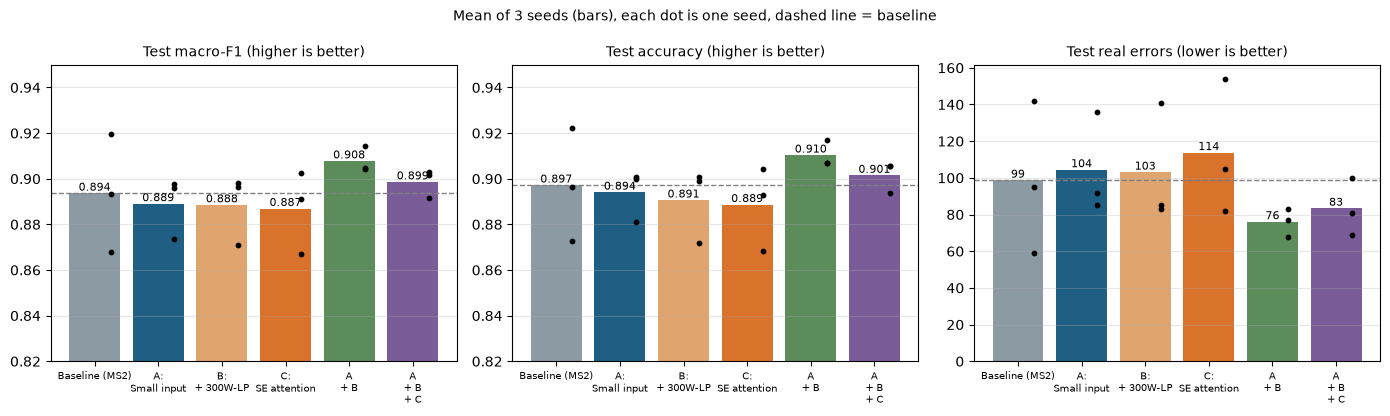

In [10]:
names = list(EXPERIMENTS)
colors = ["#8C9AA3", "#1F5F84", "#E0A56E", "#D9722B", "#5B8C5A", "#7A5C99"]
panels = [("macro_f1", "Test macro-F1 (higher is better)"), ("accuracy", "Test accuracy (higher is better)"),
          ("real_errors", "Test real errors (lower is better)")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (metric, title) in zip(axes, panels):
    for i, name in enumerate(names):
        values = [r["test"][metric] for r in runs_of(name)]
        ax.bar(i, np.mean(values), color=colors[i])
        ax.scatter([i + 0.25] * 3, values, color="black", s=10, zorder=3)          # one dot per seed
        ax.text(i, np.mean(values), f"{np.mean(values):.0f}" if metric == "real_errors" else f"{np.mean(values):.3f}",
                ha="center", va="bottom", fontsize=8)
    baseline = np.mean([r["test"][metric] for r in runs_of(names[0])])
    ax.axhline(baseline, color="gray", ls="--", lw=1)
    ax.set_xticks(range(len(names)), [n.replace(": ", ":\n").replace(" + ", "\n+ ") for n in names], fontsize=7)
    if metric != "real_errors":
        ax.set_ylim(0.82, 0.95)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.3)
plt.suptitle("Mean of 3 seeds (bars), each dot is one seed, dashed line = baseline", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "results_bars.png", dpi=200); plt.show()

### Training curves
One line per seed. The dashed line marks the start of stage 2.
Top: validation macro-F1 (higher and steadier is better). Bottom: the overfitting gap (lower is better).

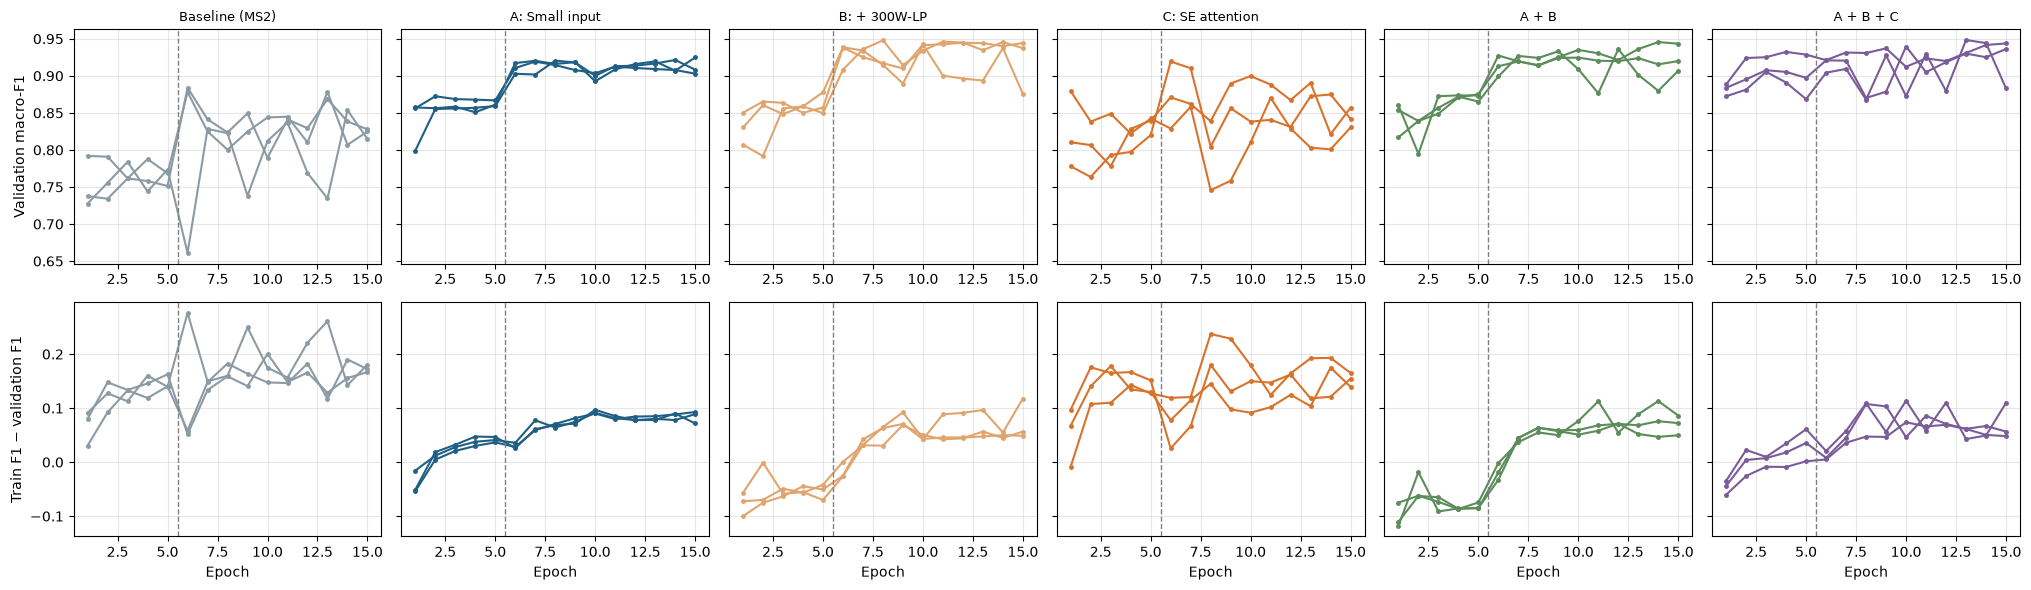

In [11]:
fig, axes = plt.subplots(2, len(names), figsize=(3.4 * len(names), 6), sharey="row")
for j, name in enumerate(names):
    for r in runs_of(name):
        epochs = range(1, len(r["history"]) + 1)
        axes[0, j].plot(epochs, [h["val_f1"] for h in r["history"]], "o-", ms=2.5, color=colors[j])
        axes[1, j].plot(epochs, [h["train_f1"] - h["val_f1"] for h in r["history"]], "o-", ms=2.5, color=colors[j])
    for ax in axes[:, j]:
        ax.axvline(CFG["stage1_epochs"] + 0.5, color="gray", ls="--", lw=1)
        ax.grid(alpha=0.3)
    axes[0, j].set_title(name, fontsize=9)
    axes[1, j].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Validation macro-F1")
axes[1, 0].set_ylabel("Train F1 − validation F1")
plt.tight_layout(); plt.savefig(FIG / "training_curves.png", dpi=200); plt.show()

## 7. Final model vs. baseline
**A + B** (small-input ResNet-18 trained with the extra 300W-LP people) has the best test scores, so it is our final model.
Below: its errors compared with the Milestone 2 baseline (mean of 3 seeds).

In [12]:
final = "A + B"
compare = {}
for name in ["Baseline (MS2)", final]:
    r = runs_of(name)
    compare[name] = {
        "accuracy": mean_std([100 * x["test"]["accuracy"] for x in r], ".1f") + " %",
        "all errors": mean_std([x["test"]["errors"] for x in r], ".0f"),
        "accepted errors (17.5°–22.5°)": mean_std([x["test"]["accepted_errors"] for x in r], ".0f"),
        "REAL errors": mean_std([x["test"]["real_errors"] for x in r], ".0f"),
        "  forward called away": f"{np.mean([x['test']['forward_called_away'] for x in r]):.0f}",
        "  away called forward": f"{np.mean([x['test']['away_called_forward'] for x in r]):.0f}",
    }
pd.DataFrame(compare)

,Baseline (MS2),A + B
accuracy,89.7 ± 2.0 %,91.0 ± 0.5 %
all errors,209 ± 41,182 ± 10
accepted errors (17.5°–22.5°),110 ± 8,106 ± 5
REAL errors,99 ± 34,76 ± 6
forward called away,64,39
away called forward,35,37


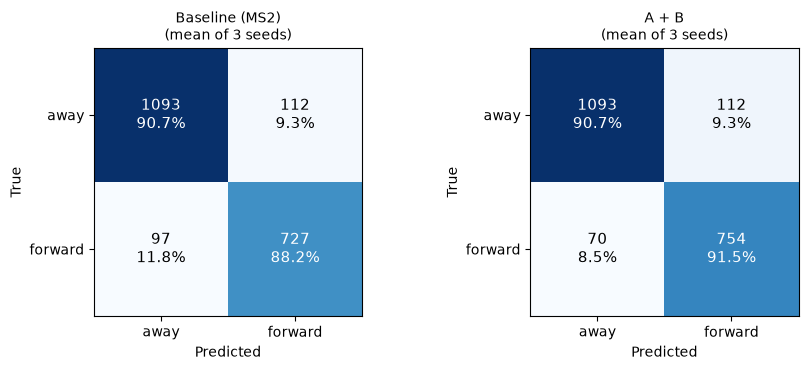

In [13]:
test_true = y[idx["test"]]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, ["Baseline (MS2)", final]):
    cm = np.mean([confusion_matrix(test_true, r["test_pred"]) for r in runs_of(name)], axis=0)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:.0f}\n{cm[i, j] / cm[i].sum():.1%}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1], ["away", "forward"]); ax.set_yticks([0, 1], ["away", "forward"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{name}\n(mean of 3 seeds)", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "confusion_matrices.png", dpi=200); plt.show()

### Where are the errors?
Test error rate by distance from the 20° line (mean of 3 seeds). The shaded bins are the accepted band (17.5°–22.5°).

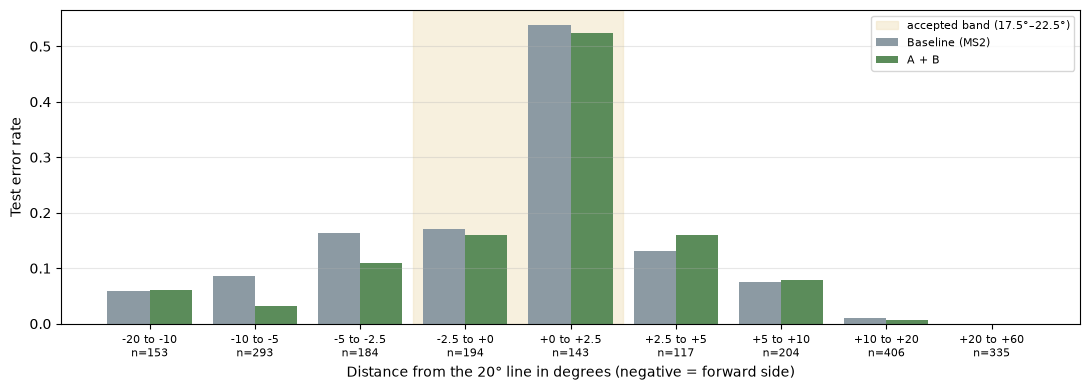

In [14]:
edges = [-20, -10, -5, -2.5, 0, 2.5, 5, 10, 20, 60]
test_dist = dist[idx["test"]]
fig, ax = plt.subplots(figsize=(11, 4))
for k, name in enumerate(["Baseline (MS2)", final]):
    rates = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (test_dist >= lo) & (test_dist < hi)
        rates.append(np.mean([(np.array(r["test_pred"])[in_bin] != test_true[in_bin]).mean() for r in runs_of(name)]))
    ax.bar(np.arange(len(rates)) + (k - 0.5) * 0.4, rates, 0.4, color=colors[0 if k == 0 else 4], label=name)
ax.axvspan(2.5, 4.5, color="#F2E6C9", alpha=0.6, zorder=0, label="accepted band (17.5°–22.5°)")
bin_sizes = [int(((test_dist >= lo) & (test_dist < hi)).sum()) for lo, hi in zip(edges[:-1], edges[1:])]
ax.set_xticks(range(len(bin_sizes)), [f"{lo:+g} to {hi:+g}\nn={n}" for lo, hi, n in zip(edges[:-1], edges[1:], bin_sizes)], fontsize=8)
ax.set_xlabel("Distance from the 20° line in degrees (negative = forward side)")
ax.set_ylabel("Test error rate")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "error_by_distance.png", dpi=200); plt.show()

## 8. Save the summary
The final model's checkpoint for the demo app is the A + B seed with the best **validation** score (the test set is not used to choose it).

In [15]:
best_seed = max(CFG["seeds"], key=lambda s: runs[f"{final} | seed {s}"]["val_f1"])
print(f"Final model: {final}, seed {best_seed}  ->  checkpoints/{re.sub(r'[^A-Za-z0-9+]+', '_', final)}_seed{best_seed}.pt")

summary = dict(config=CFG, experiments=EXPERIMENTS, results=table, final_vs_baseline=compare,
               final_model=dict(experiment=final, seed=best_seed),
               device=torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu", torch=torch.__version__)
Path("ms3_results.json").write_text(json.dumps(summary, indent=2))
print("Saved ms3_results.json")

Final model: A + B, seed 44  ->  checkpoints/A_+_B_seed44.pt
Saved ms3_results.json


## 9. Export the final model for the desktop app
The final checkpoint is converted to ONNX (`desktop_app/models/head_direction_resnet18.onnx`), the format the desktop app runs.
The ImageNet normalisation and the softmax are built in, so the app feeds raw 0–255 RGB crops of shape (N, 3, 64, 64) and gets back [P(away), P(forward)].
Then we check that the ONNX model gives the same predictions as the notebook on the test images.

In [16]:
import warnings
try:
    import onnxruntime as ort
except ImportError:                                  # e.g. in Google Colab
    subprocess.run(["pip", "-q", "install", "onnx", "onnxruntime"], check=True)
    import onnxruntime as ort

class AppModel(nn.Module):
    # The trained network with the preprocessing and the softmax built in
    def __init__(self, net):
        super().__init__()
        self.net = net.eval()
        self.register_buffer("mean", MEAN.cpu() * 255)
        self.register_buffer("std", STD.cpu() * 255)

    def forward(self, x):                            # x: (N, 3, 64, 64) RGB, values 0-255
        return self.net((x - self.mean) / self.std).softmax(dim=1)

opts = EXPERIMENTS[final]
net, _ = build_model(opts["small_input"], opts["se"])
checkpoint = CKPT / f"{re.sub(r'[^A-Za-z0-9+]+', '_', final).strip('_')}_seed{best_seed}.pt"
net.load_state_dict(torch.load(checkpoint, map_location=device))

OUT = Path("../desktop_app/models/head_direction_resnet18.onnx")
OUT.parent.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore")                   # hide PyTorch export notices
torch.onnx.export(AppModel(net.cpu()), torch.zeros(1, 3, 64, 64), OUT, input_names=["crop"], output_names=["probs"],
                  dynamic_axes={"crop": {0: "n"}, "probs": {0: "n"}}, opset_version=17, dynamo=False)
print(f"Exported {checkpoint} -> {OUT} ({OUT.stat().st_size / 1e6:.1f} MB)")

# Check: the ONNX model must give the same test predictions as the notebook
crops = images[idx["test"]].transpose(0, 3, 1, 2).astype(np.float32)
session = ort.InferenceSession(str(OUT))
probs = np.concatenate([session.run(None, {"crop": crops[i:i + 256]})[0] for i in range(0, len(crops), 256)])
same = (probs.argmax(1) == np.array(runs[f"{final} | seed {best_seed}"]["test_pred"])).sum()
print(f"ONNX vs. notebook on the {len(crops)} test images: {same} identical predictions ({same / len(crops):.2%})")

Exported checkpoints\A_+_B_seed44.pt -> ..\desktop_app\models\head_direction_resnet18.onnx (44.7 MB)


ONNX vs. notebook on the 2029 test images: 2028 identical predictions (99.95%)
